# 01 — CICIDS-2017 Exploratory Data Analysis & Preprocessing Audit
This notebook executes the sanitization and chronological splitting pipeline and visualizes:
1. **Preprocessing Audit:** Rows cleaned (`NaN`/`Inf` removed) and features pruned (`|r| > 0.98` & zero-variance).
2. **Session & Class Imbalance:** Flow counts across the 8 Monday–Friday CSVs, 15 granular labels, and 8 macro classes.
3. **Chronological Attack Timeline:** Session-by-session heatmap confirming why Monday is pure `BENIGN`.
4. **Feature Distributions & Post-Pruning Correlation:** KDE distributions (`BENIGN` vs. Attacks) and clean correlation heatmap.
5. **Causal Split Verification:** Train (`50%`) vs. Clean Validation (`15%`) vs. Test Replay (`35%`) proportions.

In [1]:
import sys
import json
from pathlib import Path

ML_SERVICE_ROOT = Path.cwd().resolve()
if ML_SERVICE_ROOT.name == "notebooks":
    ML_SERVICE_ROOT = ML_SERVICE_ROOT.parent
if str(ML_SERVICE_ROOT) not in sys.path:
    sys.path.insert(0, str(ML_SERVICE_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
from src.config import settings
from src.logger import setup_logging

setup_logging()
print("Connected to ML Service Root:", ML_SERVICE_ROOT)
from src.preprocessing.clean_cicids import run_cleaning
from src.preprocessing.build_splits import build_chronological_splits

Connected to ML Service Root: C:\Users\gupta\Documents\College\BTP\code\ea-idrs\ml-service


In [2]:
clean_parquet = settings.PROCESSED_DIR / "cicids2017_clean.parquet"
audit_json = settings.PROCESSED_DIR / "preprocessing_audit.json"

if not clean_parquet.exists() or not audit_json.exists():
    run_cleaning()

if not (settings.SPLITS_DIR / "split_metadata.json").exists():
    build_chronological_splits()

with open(audit_json, encoding="utf-8") as f:
    audit = json.load(f)

with open(settings.SPLITS_DIR / "split_metadata.json", encoding="utf-8") as f:
    split_meta = json.load(f)

df = pd.read_parquet(clean_parquet, engine="pyarrow")
print(f"Loaded cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")

Loaded cleaned dataset: 2,827,876 rows x 51 columns


### 1. Preprocessing Audit: Row Sanitization & Feature Pruning Summary

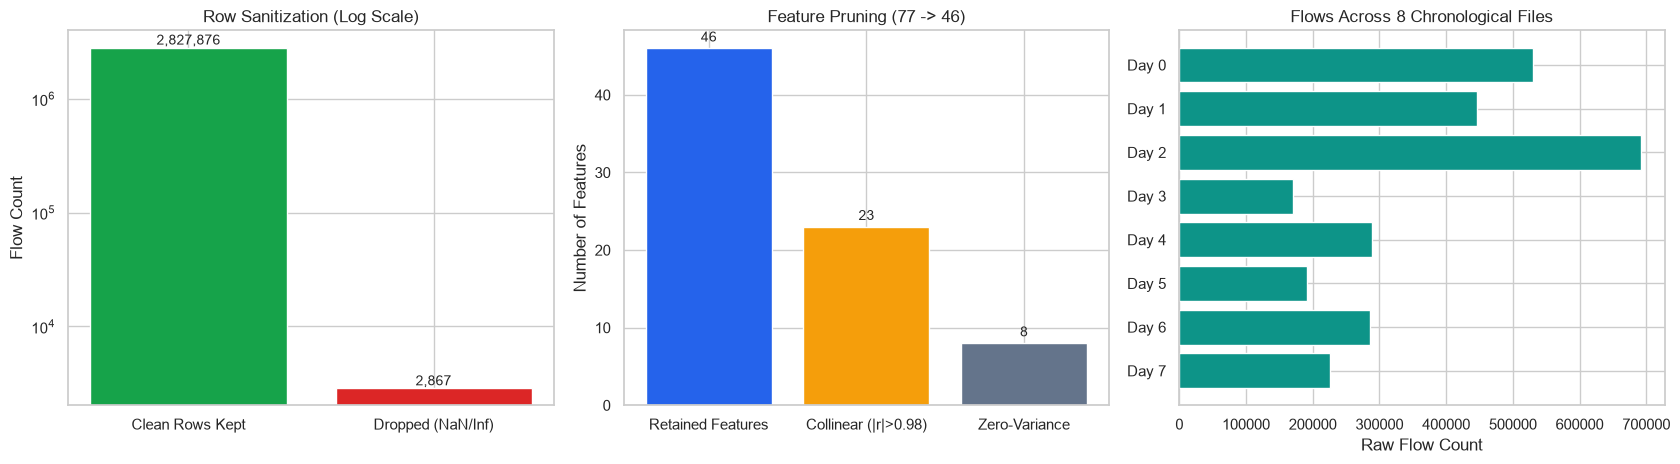

Collinear features removed: ['Total Backward Packets', 'Total Length of Bwd Packets', 'Bwd Packet Length Std', 'Fwd IAT Total', 'Fwd IAT Max', 'Bwd Header Length', 'Fwd Packets/s', 'Packet Length Std', 'SYN Flag Count', 'CWE Flag Count', 'ECE Flag Count', 'Average Packet Size', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'act_data_pkt_fwd', 'min_seg_size_forward', 'Idle Mean', 'Idle Max', 'Idle Min']
Zero-variance features removed: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Panel A: Rows Kept vs Dropped (NaN/Inf)
row_labels = ["Clean Rows Kept", "Dropped (NaN/Inf)"]
row_vals = [audit["clean_total_rows"], audit["dropped_nan_inf_rows"]]
bars0 = axes[0].bar(row_labels, row_vals, color=["#16a34a", "#dc2626"])
axes[0].set_yscale("log")
axes[0].set_title("Row Sanitization (Log Scale)")
axes[0].set_ylabel("Flow Count")
for b in bars0:
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height(), f"{int(b.get_height()):,}", ha="center", va="bottom", fontsize=10)

# Panel B: Feature Reduction Breakdown
feat_labels = ["Retained Features", "Collinear (|r|>0.98)", "Zero-Variance"]
feat_vals = [
    audit["final_feature_count"],
    len(audit["collinear_dropped"]),
    len(audit["zero_variance_dropped"]),
]
bars1 = axes[1].bar(feat_labels, feat_vals, color=["#2563eb", "#f59e0b", "#64748b"])
axes[1].set_title(f"Feature Pruning ({audit['initial_feature_count']} -> {audit['final_feature_count']})")
axes[1].set_ylabel("Number of Features")
for b in bars1:
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.5, f"{int(b.get_height())}", ha="center", va="bottom", fontsize=10)

# Panel C: Flows per Chronological CSV File
short_names = [f"Day {i}" for i in range(len(audit["file_row_counts"]))]
file_vals = list(audit["file_row_counts"].values())
axes[2].barh(short_names[::-1], file_vals[::-1], color="#0d9488")
axes[2].set_title("Flows Across 8 Chronological Files")
axes[2].set_xlabel("Raw Flow Count")

plt.tight_layout()
plt.show()
print("Collinear features removed:", audit["collinear_dropped"])
print("Zero-variance features removed:", audit["zero_variance_dropped"])

### 2. Class Imbalance Analysis (15 Granular Labels vs. 8 Macro Classes)

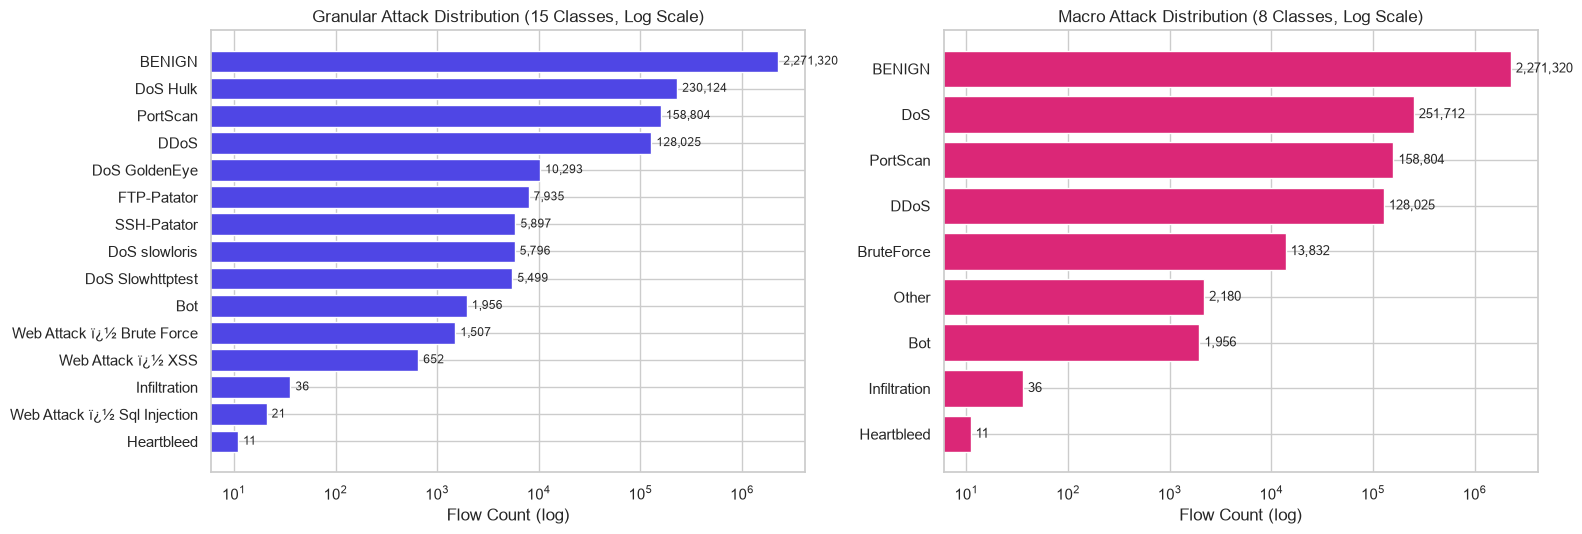

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

gran = pd.Series(audit["granular_class_counts"]).sort_values(ascending=True)
axes[0].barh(gran.index, gran.values, color="#4f46e5")
axes[0].set_xscale("log")
axes[0].set_title("Granular Attack Distribution (15 Classes, Log Scale)")
axes[0].set_xlabel("Flow Count (log)")
for idx, val in enumerate(gran.values):
    axes[0].text(val * 1.12, idx, f"{val:,}", va="center", fontsize=8.5)

macro = pd.Series(audit["macro_class_counts"]).sort_values(ascending=True)
axes[1].barh(macro.index, macro.values, color="#db2777")
axes[1].set_xscale("log")
axes[1].set_title("Macro Attack Distribution (8 Classes, Log Scale)")
axes[1].set_xlabel("Flow Count (log)")
for idx, val in enumerate(macro.values):
    axes[1].text(val * 1.12, idx, f"{val:,}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

### 3. Chronological Capture Timeline (Monday to Friday Attack Presence)

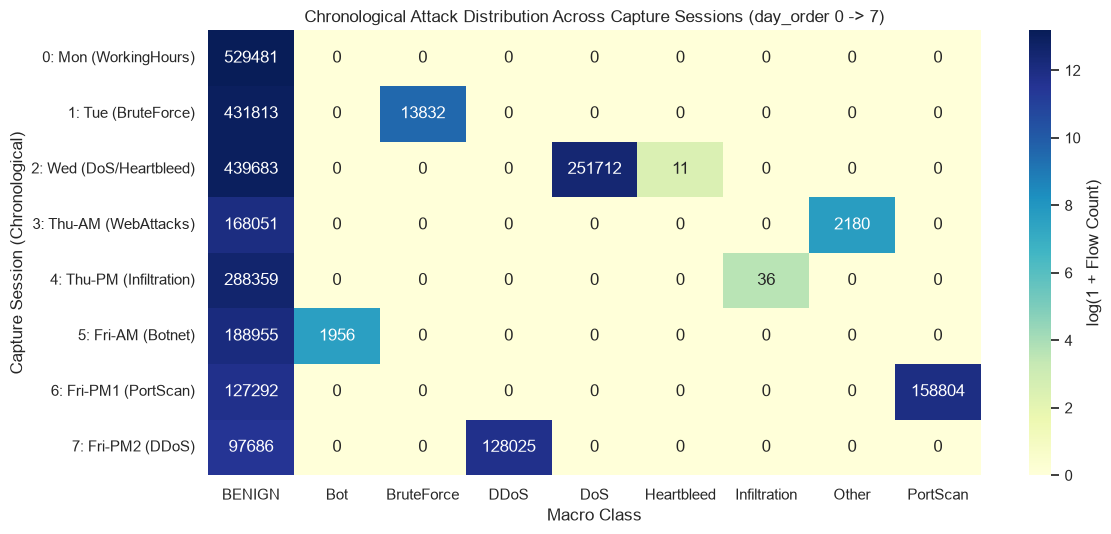

In [5]:
session_labels = [
    "0: Mon (WorkingHours)",
    "1: Tue (BruteForce)",
    "2: Wed (DoS/Heartbleed)",
    "3: Thu-AM (WebAttacks)",
    "4: Thu-PM (Infiltration)",
    "5: Fri-AM (Botnet)",
    "6: Fri-PM1 (PortScan)",
    "7: Fri-PM2 (DDoS)",
]
ct = pd.crosstab(df["day_order"], df["Macro_Label"])
ct.index = [session_labels[i] for i in ct.index]

plt.figure(figsize=(12, 5.5))
sns.heatmap(np.log1p(ct), annot=ct, fmt="d", cmap="YlGnBu", cbar_kws={"label": "log(1 + Flow Count)"})
plt.title("Chronological Attack Distribution Across Capture Sessions (day_order 0 -> 7)")
plt.ylabel("Capture Session (Chronological)")
plt.xlabel("Macro Class")
plt.tight_layout()
plt.show()

### 4. Post-Pruning Correlation Matrix & Key Feature Distributions (`BENIGN` vs. Attacks)

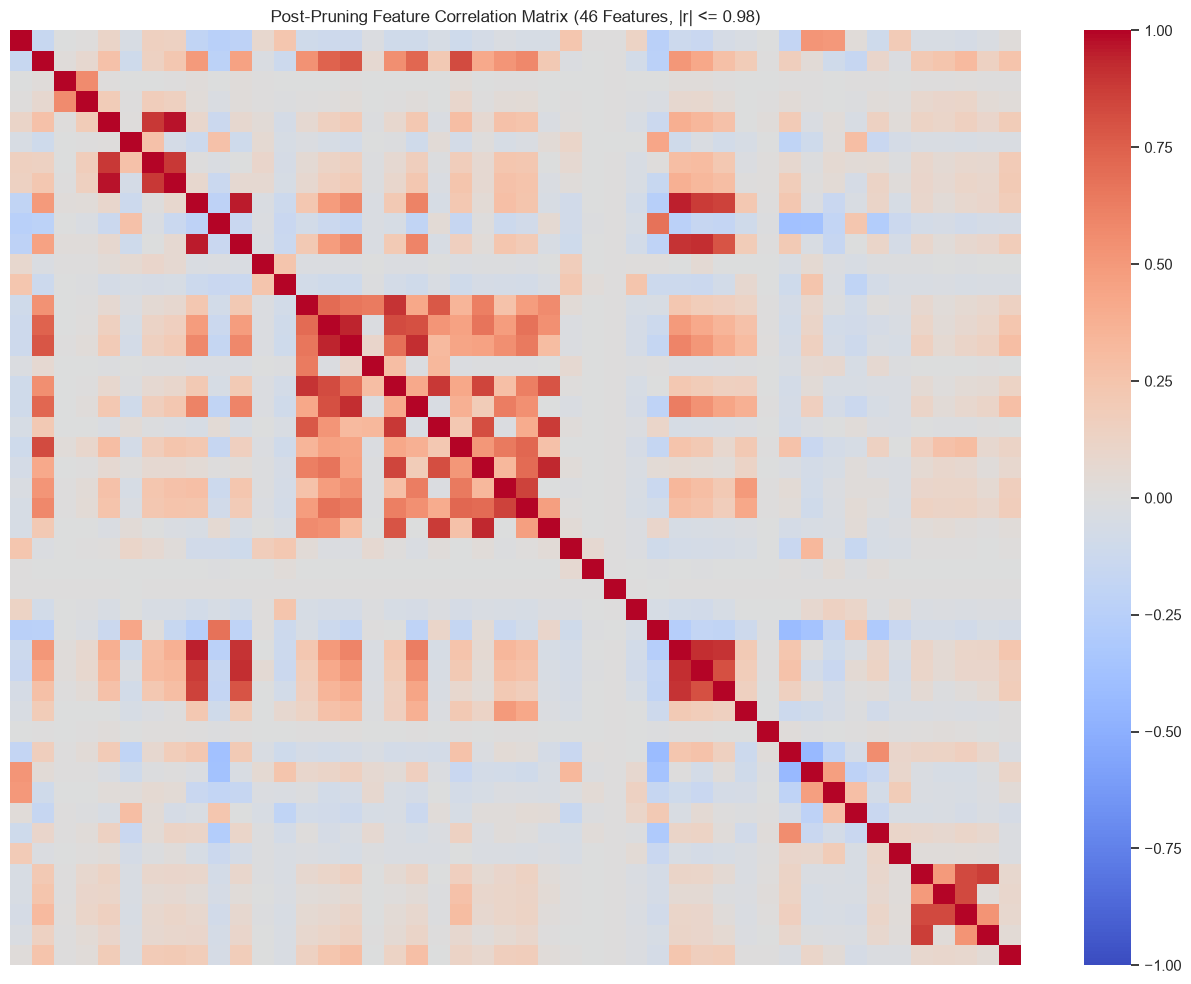

C:\Users\gupta\AppData\Local\Temp\ipykernel_32168\753744853.py:22: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(vals, ax=ax, label=cls, fill=True, alpha=0.25)
C:\Users\gupta\AppData\Local\Temp\ipykernel_32168\753744853.py:22: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(vals, ax=ax, label=cls, fill=True, alpha=0.25)


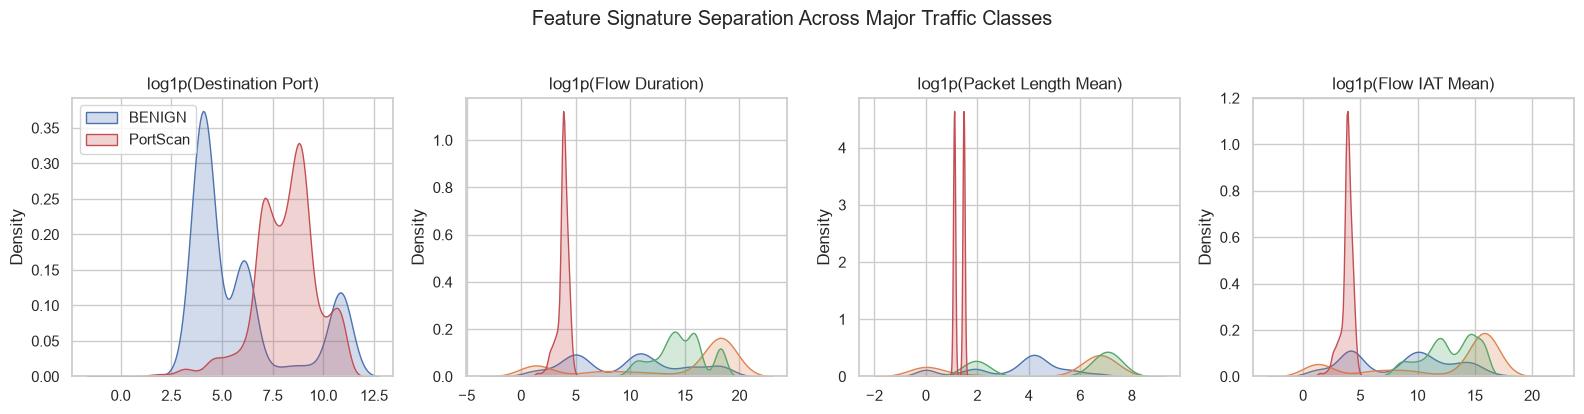

In [6]:
feature_cols = split_meta["feature_cols"]
corr = df[feature_cols].sample(n=50_000, random_state=settings.RANDOM_SEED).corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
plt.title(f"Post-Pruning Feature Correlation Matrix ({len(feature_cols)} Features, |r| <= {settings.CORR_THRESHOLD})")
plt.tight_layout()
plt.show()

# Feature shift/separation preview across major classes
top_preview_cols = [
    c for c in ["Destination Port", "Flow Duration", "Packet Length Mean", "Flow IAT Mean"]
    if c in df.columns
]
major_classes = ["BENIGN", "DoS", "DDoS", "PortScan"]
sub = df[df["Macro_Label"].isin(major_classes)].groupby("Macro_Label").sample(n=2000, random_state=42)

fig, axes = plt.subplots(1, len(top_preview_cols), figsize=(16, 4))
for ax, col in zip(axes, top_preview_cols):
    for cls in major_classes:
        vals = np.log1p(np.clip(sub[sub["Macro_Label"] == cls][col], 0, None))
        sns.kdeplot(vals, ax=ax, label=cls, fill=True, alpha=0.25)
    ax.set_title(f"log1p({col})")
    ax.set_xlabel("")
axes[0].legend()
plt.suptitle("Feature Signature Separation Across Major Traffic Classes", y=1.03)
plt.tight_layout()
plt.show()

### 5. Chronological Split Proportions (`train` / `val_clean` / `test_stream`)

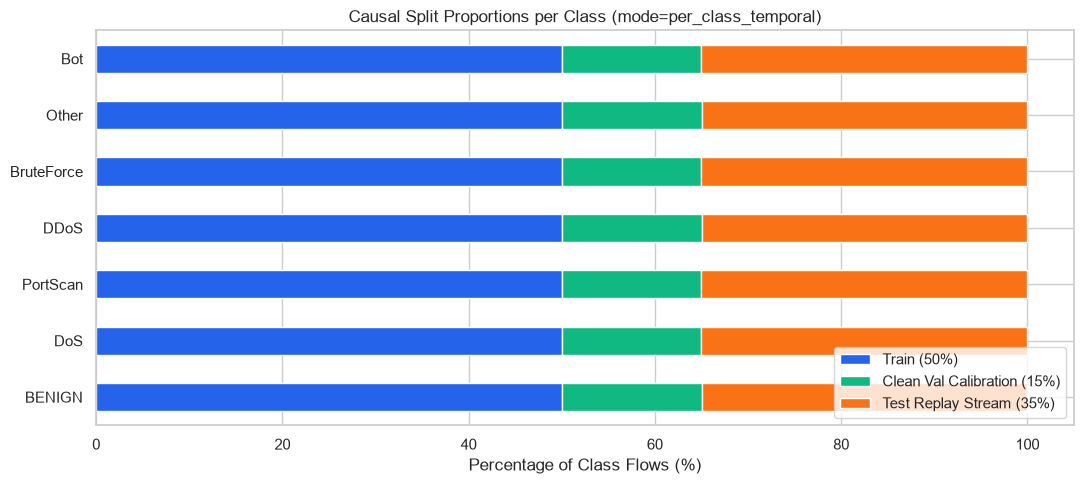

,train,val_clean,test
BENIGN,1135660,340698,794962
DoS,125856,37756,88100
PortScan,79402,23820,55582
DDoS,64012,19204,44809
BruteForce,6916,2074,4842
Other,1090,327,763
Bot,978,293,685


In [7]:
split_dist = pd.DataFrame(split_meta["class_distribution_by_split"]).fillna(0)
split_pct = split_dist.div(split_dist.sum(axis=1), axis=0) * 100.0

ax = split_pct.plot(kind="barh", stacked=True, figsize=(11, 5), color=["#2563eb", "#10b981", "#f97316"])
ax.set_title(f"Causal Split Proportions per Class (mode={split_meta['split_mode']})")
ax.set_xlabel("Percentage of Class Flows (%)")
ax.legend(["Train (50%)", "Clean Val Calibration (15%)", "Test Replay Stream (35%)"], loc="lower right")
plt.tight_layout()
plt.show()
display(split_dist.astype(int))